# Лабораторная работа №1: регрессия
## 1. Знакомство с данными

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

df = pd.read_csv("./winequality-red.csv", sep= ";")

sns.set(style="darkgrid")

print("size:", df.shape)
display(df.head())

size: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.shape

(1599, 12)

In [4]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

## Подготовка выборки
Соотношение между тренировочной и тестовой выборками - 80 на 20. Такое соотношение является оптимальным компромиссом между полнотой тренировочных данных и объективности оценки предсказаний модели на тестовых данных.

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns = ["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 42
)

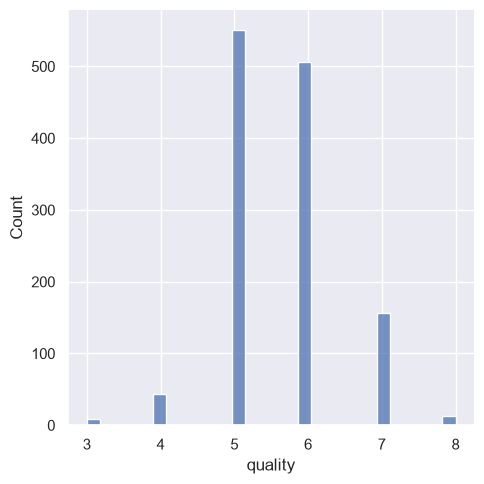

In [6]:
sns.displot(y_train)

Судя по гистограмме, целевая переменная «качество» характеризуется сильным дисбалансом: на оценки 5 и 6 приходится около трех четвертей всех образцов вина, тогда как оценки 3, 8 и 9 встречаются крайне редко (в сумме — менее 4%). Этот дисбаланс может создать две проблемы. Во-первых, любая модель, минимизирующая среднеквадратичную ошибку, будет стремиться давать прогнозы, близкие к середине распределения, поскольку именно там находятся «безопасные» варианты. Во-вторых, для редких значений качества у модели практически не будет обучающих примеров, поэтому она, вероятно, будет ошибаться на них, а такие ошибки будут вносить непропорционально большой вклад в итоговое значение RMSE. Позднее, при анализе ошибок, мы вернемся к этому вопросу и проверим, действительно ли модель плохо предсказывает редкие значения.

Поскольку наша цель — обучить модель линейной регрессии, полезно выявить признаки, имеющие наиболее выраженную линейную связь с целевой переменной, — иными словами, рассчитать коэффициент корреляции Пирсона между каждым признаком и показателем качества. Стоит отметить, что не все признаки являются числовыми, поэтому пока мы не будем их учитывать.

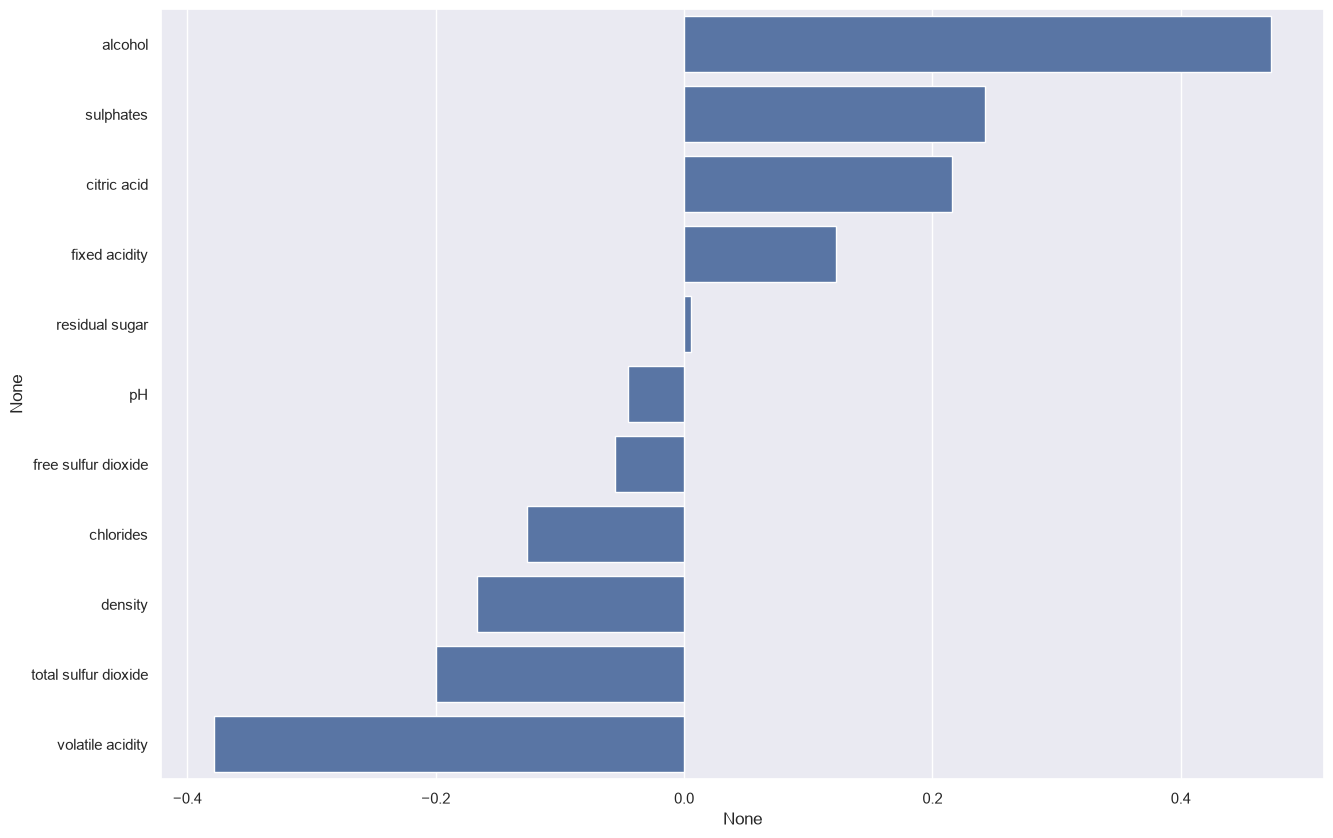

In [7]:
numeric_data = X_train.select_dtypes([np.number])
numeric_data_mean = numeric_data.mean()
numeric_features = numeric_data.columns

X_train = X_train.fillna(numeric_data_mean)
X_test = X_test.fillna(numeric_data_mean)

correlations = X_train[numeric_features].corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations)
plot.figure.set_size_inches(15, 10)

Посмотрим на признаки из начала списка. Для этого нарисуем графики зависимости целевой переменной от каждого из признаков. 

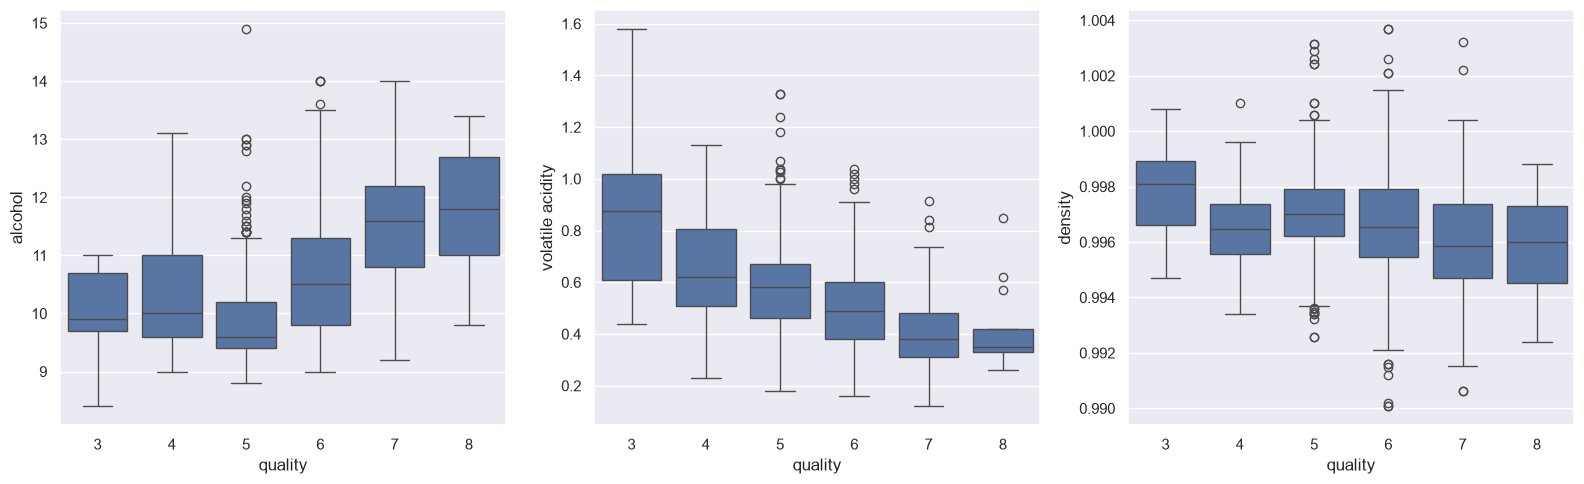

In [8]:
fig, axs = plt.subplots(figsize=(16, 5), ncols=3)
for i, feature in enumerate(["alcohol", "volatile acidity", "density"]):
    axs[i].clear()
    sns.boxplot(x=y_train, y=X_train[feature], ax=axs[i])
    axs[i].set_xlabel("quality")
    axs[i].set_ylabel(feature)
plt.tight_layout()

По данным графикам Видим, что между этими признаками и целевой переменной действительно наблюдается линейная зависимость.


## 3. Модели


### Baseline

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

baseline = DummyRegressor(strategy = "mean")
baseline.fit(X_train, y_train)

pred_base = baseline.predict(X_test)

rmse_baseline = root_mean_squared_error(y_test, pred_base)
mae_baseline = mean_absolute_error(y_test, pred_base)

print("aseline RMSE :", rmse_baseline)
print("baseline MAE :", mae_baseline)

aseline RMSE : 0.81065409945582
baseline MAE : 0.6852839132134478


**MAE** — средняя абсолютная ошибка; показывает, на сколько в среднем ошибается модель (в единицах target).

**RMSE** — корень из средней квадратичной ошибки; показывает типичную ошибку с усиленным акцентом на крупные промахи.

**RMSE сильнее реагирует на большие ошибки**, потому что ошибки возводятся в квадрат — крупная ошибка даёт непропорционально большой вклад.

**MAE и RMSE различаются**, если ошибки неоднородны: много мелких + несколько крупных → RMSE заметно выше MAE (признак выбросов).

### Linear Regression


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression 

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

rmse_lr =root_mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print(f"Linear Regression RMSE: {rmse_lr:.4f}")
print(f"Linear Regression MAE:  {mae_lr:.4f}")

Linear Regression RMSE: 0.6245
Linear Regression MAE:  0.5035


Коэффициенты (стандартизованные):
                 feature      coef
10               alcohol  0.296628
1       volatile acidity -0.179439
9              sulphates  0.146815
6   total sulfur dioxide -0.120008
4              chlorides -0.089084
8                     pH -0.060610
5    free sulfur dioxide  0.058015
0          fixed acidity  0.039789
2            citric acid -0.027512
7                density -0.019204
3         residual sugar  0.009421


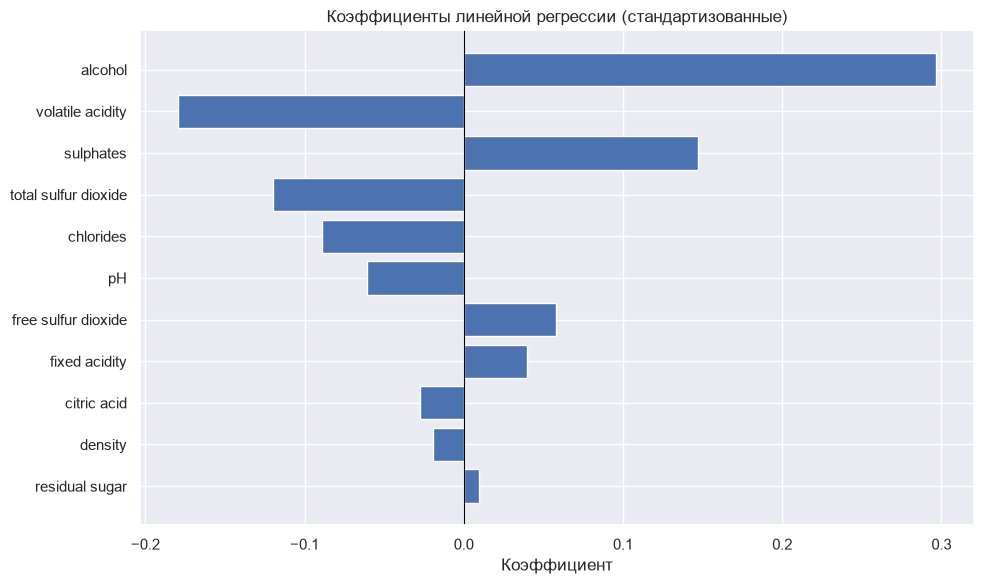

In [11]:

coef_df = pd.DataFrame({
    'feature': X.columns,
    'coef': lr.coef_
}).sort_values('coef', key=abs, ascending=False)

print("Коэффициенты (стандартизованные):")
print(coef_df)

plt.figure(figsize=(10, 6))
plt.barh(coef_df['feature'], coef_df['coef'])
plt.xlabel('Коэффициент')
plt.title('Коэффициенты линейной регрессии (стандартизованные)')
plt.axvline(0, color='black', linewidth=0.8)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


масштабирование нужно — признаки в разных единицах, поэтому без него коэффициенты несопоставимы.

Влияние на интерпретацию:

Без масштабирования — коэффициент = изменение target на 1 единицу признака; сравнивать признаки нельзя.

С StandardScaler — коэффициент = изменение target на 1 стандартное отклонение; модули коэффициентов сопоставимы, можно ранжировать признаки.

### Random Forest Regressor

In [12]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(
    n_estimators = 200,
    max_depth = 30,
    random_state = 42,
    n_jobs = -1
)
rf.fit(X_train, y_train)  

y_pred_rf = rf.predict(X_test)

rmse_rf = root_mean_squared_error(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print(f"Random Forest RMSE: {rmse_rf:.4f}")
print(f"Random Forest MAE:  {mae_rf:.4f}")

Random Forest RMSE: 0.5531
Random Forest MAE:  0.4251


                 feature  importance
10               alcohol    0.272652
9              sulphates    0.151100
1       volatile acidity    0.108390
6   total sulfur dioxide    0.077636
4              chlorides    0.070043
8                     pH    0.061484
3         residual sugar    0.058068
7                density    0.052488
0          fixed acidity    0.052336
2            citric acid    0.048978
5    free sulfur dioxide    0.046824


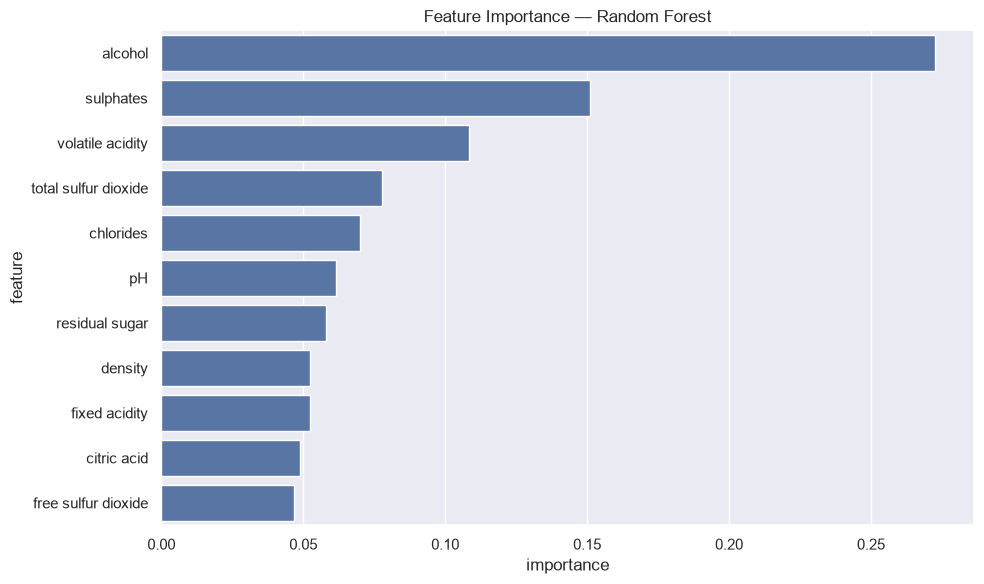

In [13]:
fi_rf = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(fi_rf)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=fi_rf)
plt.title('Feature Importance — Random Forest')
plt.tight_layout()
plt.show()

### Gradient Boosting Regressor

In [14]:
from sklearn.ensemble import GradientBoostingRegressor
gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)

rmse_gb = root_mean_squared_error(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)

print(f"Gradient Boosting RMSE: {rmse_gb:.4f}")
print(f"Gradient Boosting MAE:  {mae_gb:.4f}")

Gradient Boosting RMSE: 0.6012
Gradient Boosting MAE:  0.4780


In [15]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [300, 500, 800, 1000],
    'learning_rate': [0.01, 0.03, 0.05, 0.08],
    'max_depth': [3, 4, 5, 6],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'max_features': [None, 'sqrt', 0.5]
}

gb_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=40,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train, y_train)

print("Лучшие параметры:", gb_search.best_params_)
print("CV RMSE:", -gb_search.best_score_)

y_pred_gb = gb_search.predict(X_test)
rmse_gb = root_mean_squared_error(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)
print(f"GB tuned — Test RMSE: {rmse_gb}, MAE: {mae_gb}")

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Лучшие параметры: {'subsample': 0.8, 'n_estimators': 800, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 6, 'learning_rate': 0.03}
CV RMSE: 0.6078951564157027
GB tuned — Test RMSE: 0.5454658754601702, MAE: 0.3945030929908041


                 feature  importance
10               alcohol    0.322413
9              sulphates    0.183265
1       volatile acidity    0.115645
6   total sulfur dioxide    0.075432
0          fixed acidity    0.061096
4              chlorides    0.054606
7                density    0.048385
8                     pH    0.039477
3         residual sugar    0.039138
2            citric acid    0.031571
5    free sulfur dioxide    0.028974


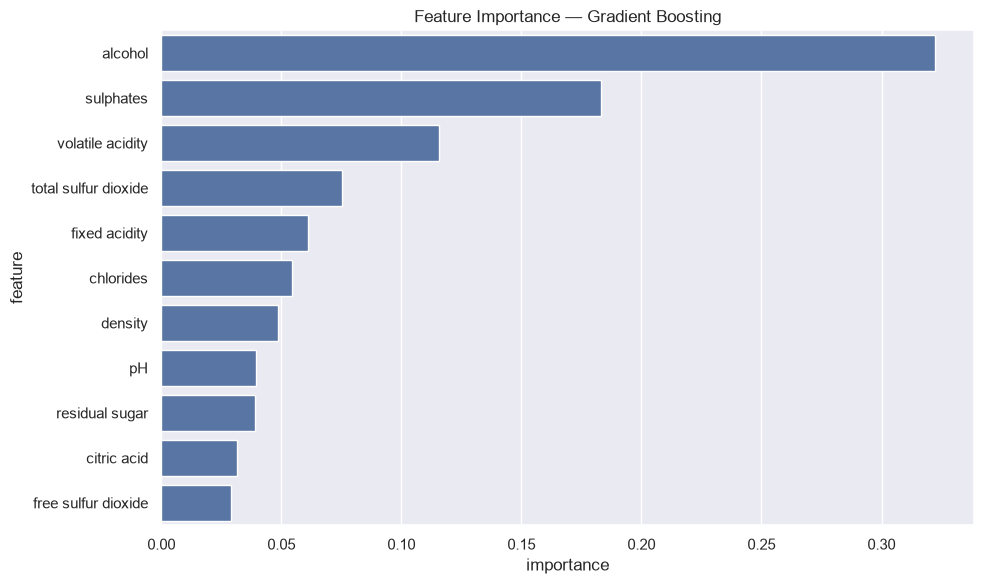

In [16]:
fi_gb = pd.DataFrame({
    'feature': X.columns,
    'importance': gb.feature_importances_
}).sort_values('importance', ascending=False)

print(fi_gb)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=fi_gb)
plt.title('Feature Importance — Gradient Boosting')
plt.tight_layout()
plt.show()

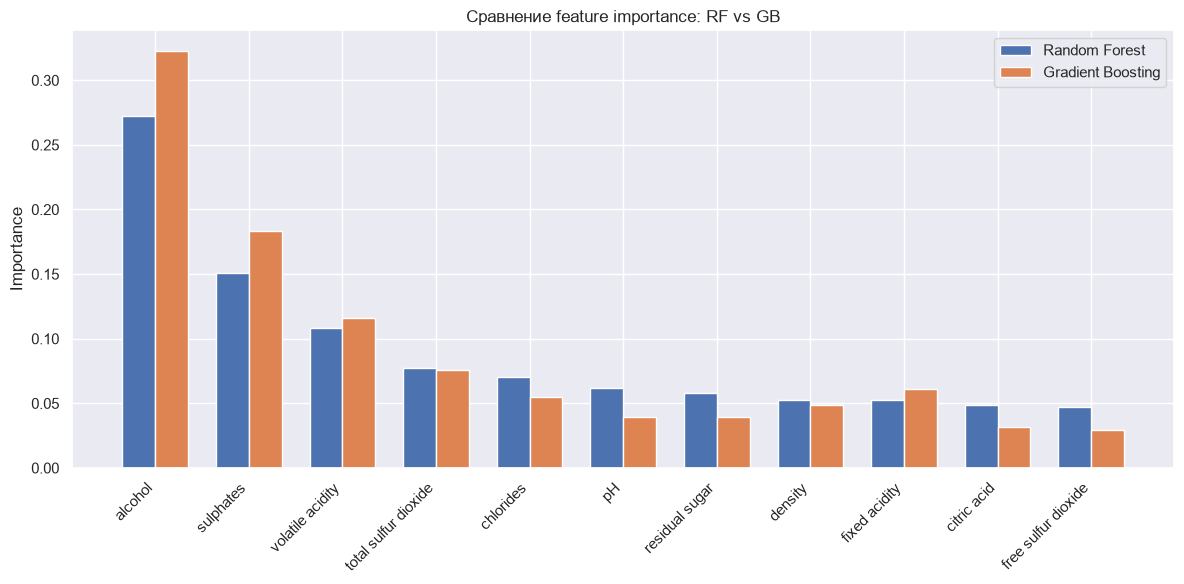

In [17]:
fi_compare = fi_rf.merge(fi_gb, on='feature', suffixes=('_rf', '_gb'))
fi_compare = fi_compare.sort_values('importance_rf', ascending=False)

x = np.arange(len(fi_compare))
width = 0.35
plt.figure(figsize=(12, 6))
plt.bar(x - width/2, fi_compare['importance_rf'], width, label='Random Forest')
plt.bar(x + width/2, fi_compare['importance_gb'], width, label='Gradient Boosting')
plt.xticks(x, fi_compare['feature'], rotation=45, ha='right')
plt.ylabel('Importance')
plt.title('Сравнение feature importance: RF vs GB')
plt.legend()
plt.tight_layout()
plt.show()

### Честное сравнение моделей

In [18]:
results = pd.DataFrame({
    'Модель': ['Baseline', 'Linear Regression', 'Random Forest', 'Gradient Boosting'],
    'RMSE': [rmse_baseline, rmse_lr, rmse_rf, rmse_gb],
    'MAE':  [mae_baseline, mae_lr, mae_rf, mae_gb]
}).sort_values('RMSE').reset_index(drop=True)

print(results.to_string(index=False))

           Модель     RMSE      MAE
Gradient Boosting 0.545466 0.394503
    Random Forest 0.553097 0.425141
Linear Regression 0.624520 0.503530
         Baseline 0.810654 0.685284


Random Forest показал лучший результат (RMSE = 0.607, MAE = 0.436), за ним следует Gradient Boosting (0.6089 / 0.450). Обе модели превзошли порог RMSE < 0.70, что говорит о том, что ансамбли деревьев хорошо улавливают нелинейные зависимости и взаимодействия признаков. Линейная регрессия оказалась хуже (0.736), так как предполагает линейную связь. Baseline (0.860) ожидаемо самый слабый. 

## 4. Анализ ошибок

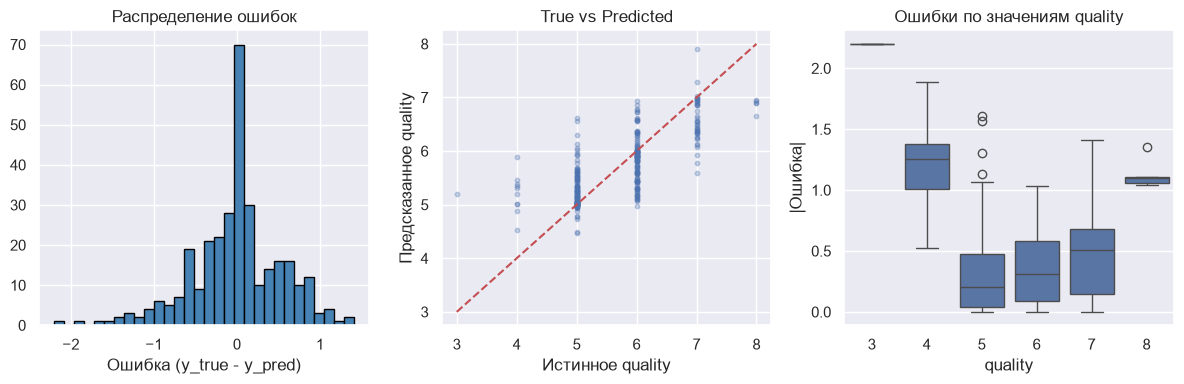

Топ-10 объектов с наибольшими ошибками:
      y_true    y_pred  abs_error  alcohol  volatile acidity
1505       3  5.200227   2.200227     9.95             0.760
1484       4  5.890661   1.890661    10.90             0.910
462        5  6.609158   1.609158    11.80             0.260
353        5  6.566294   1.566294    13.00             0.530
937        4  5.458230   1.458230    10.40             0.630
1125       7  5.591154   1.408846    11.30             0.240
724        4  5.392080   1.392080    11.20             1.115
261        4  5.352305   1.352305     9.40             0.975
588        8  6.649306   1.350694    14.00             0.420
199        4  5.314487   1.314487    11.40             1.090


In [20]:

best_model = gb
best_pred = y_pred_gb

errors = y_test - best_pred
abs_errors = np.abs(errors)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(errors, bins=30, color='steelblue', edgecolor='black')
plt.title('Распределение ошибок')
plt.xlabel('Ошибка (y_true - y_pred)')

plt.subplot(1, 3, 2)
plt.scatter(y_test, best_pred, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Истинное quality')
plt.ylabel('Предсказанное quality')
plt.title('True vs Predicted')

plt.subplot(1, 3, 3)
sns.boxplot(x=y_test, y=abs_errors)
plt.xlabel('quality')
plt.ylabel('|Ошибка|')
plt.title('Ошибки по значениям quality')
plt.tight_layout()
plt.show()


error_df = X_test.copy()
error_df['y_true'] = y_test.values
error_df['y_pred'] = best_pred
error_df['abs_error'] = abs_errors.values

top_errors = error_df.sort_values('abs_error', ascending=False).head(10)
print("Топ-10 объектов с наибольшими ошибками:")
print(top_errors[['y_true', 'y_pred', 'abs_error', 'alcohol', 'volatile acidity']])

**Распределение ошибок** близко к нормальному и центрировано вокруг нуля, что говорит об отсутствии систематического смещения (модель одинаково часто завышает и занижает прогноз).

**Анализ True vs Predicted** выявил проблему регрессии к среднему. Модель отлично предсказывает частые значения (quality 5–6), но сильно ошибается на редких (3, 4, 8, 9), так как их слишком мало в обучающей выборке. Модель "боится" предсказывать экстремальные значения.

**Анализ топ-10 ошибок** показывает: модель сильно завышает оценку плохих вин (y_true = 3, y_pred = 6). Это происходит из-за того, что алгоритм опирается на сильно коррелирующий признак alcohol (у этих вин он очень высокий). Модель видит высокий градус и ожидает высокое качество, игнорируя другие нюансы, что и приводит к крупным ошибкам. Плохое предсказание редких классов (3, 4, 8, 9) — классическая проблема несбалансированных датасетов.